# Analisis Emosi Komentar YouTube dengan IndoBERT

##Alur Proses (Pipeline)
1.  **Data Preparation**: Memuat data latih (Twitter Emotion Dataset) dan data target (YouTube Comments).
2.  **Preprocessing**: Membersihkan teks dari noise (stopwords, singkatan, simbol) agar lebih mudah dipahami model.
3.  **Fine-tuning BERT**: Melatih ulang model IndoBERT agar spesifik mengenali emosi bahasa Indonesia.
4.  **Evaluasi**: Mengukur akurasi model pada data uji.
5.  **Inference (Prediksi)**: Menerapkan model ke komentar YouTube.
6.  **Visualisasi & Insight**: Menganalisis hasil menggunakan Grafik Distribusi dan WordCloud.

---

#Tahap 1: Instalasi & Persiapan Lingkungan

In [19]:
# @title Install Library Pendukung
# Menginstall library 'transformers' untuk model BERT, 'datasets' untuk manajemen data,
# dan library visualisasi seperti 'wordcloud'.
!pip install transformers datasets torch scikit-learn pandas numpy tqdm nltk wordcloud matplotlib seaborn Sastrawi -q

print("✅ Instalasi selesai.")

✅ Instalasi selesai.


In [20]:
# @title Import Library
import pandas as pd
import numpy as np
import torch
import re
import string
import html
import nltk
import matplotlib.pyplot as plt
import seaborn as sns
from wordcloud import WordCloud
from nltk.corpus import stopwords
from torch.utils.data import Dataset
from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification,
    TrainingArguments,
    Trainer
)
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
from tqdm import tqdm
import warnings
warnings.filterwarnings('ignore')

nltk.download('stopwords', quiet=True)

# Setup GPU jika tersedia agar training lebih cepat
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"✅ Perangkat yang digunakan: {device}")
if torch.cuda.is_available():
    print(f"   GPU Model: {torch.cuda.get_device_name(0)}")

✅ Perangkat yang digunakan: cuda
   GPU Model: Tesla T4


# Tahap 2: Memuat Dataset
Kita membutuhkan 3 jenis file:
1.  **Dataset Latih (Twitter)**: `Twitter_Emotion_Dataset.csv` (Format: `label,tweet`)
2.  **Kamus Preprocessing**: `stoplist.txt` (Kata hubung) & `singkatan-lib.csv` (Kamus gaul)
3.  **Dataset Target (YouTube)**: `youtube_comments.csv`

In [21]:
# @title Upload File Dataset & Kamus
from google.colab import files

print("📥 Silakan upload file berikut:")
print("   1. Twitter_Emotion_Dataset.csv")
print("   2. stoplist.txt")
print("   3. singkatan-lib.csv")
print("   4. youtube_comments.csv")

uploaded = files.upload()

📥 Silakan upload file berikut:
   1. Twitter_Emotion_Dataset.csv
   2. stoplist.txt
   3. singkatan-lib.csv
   4. youtube_comments.csv


Saving stoplist.txt to stoplist (1).txt
Saving Twitter_Emotion_Dataset.csv to Twitter_Emotion_Dataset (1).csv
Saving singkatan-lib.csv to singkatan-lib (1).csv
Saving youtube_comments.csv to youtube_comments (1).csv


In [22]:
# @title Load Data Training (Twitter)
# Membaca file CSV dataset Twitter
try:
    df_twitter = pd.read_csv('Twitter_Emotion_Dataset.csv')
    # Pastikan nama kolom standar
    df_twitter.columns = ['label', 'tweet']
    print("✅ Dataset Twitter berhasil dimuat.")
    print(f"   Jumlah data: {len(df_twitter)} tweet")
    print(f"   Distribusi Label:\n{df_twitter['label'].value_counts()}")
except Exception as e:
    print(f"❌ Gagal memuat dataset Twitter: {e}")

✅ Dataset Twitter berhasil dimuat.
   Jumlah data: 4401 tweet
   Distribusi Label:
label
anger      1101
happy      1017
sadness     997
fear        649
love        637
Name: count, dtype: int64


In [23]:
# @title Load Kamus Stopwords & Singkatan
# Memuat kata-kata yang akan dihapus (stopwords) dan singkatan yang akan diperbaiki

# 1. Load Stopwords
nltk_stop = set(stopwords.words('indonesian'))
try:
    with open('stoplist.txt', encoding='utf-8') as f:
        custom_stop = set([w.strip().lower() for w in f.readlines()])
    all_stopwords = nltk_stop.union(custom_stop)
    print(f"✅ Stopwords dimuat: {len(all_stopwords)} kata")
except:
    all_stopwords = nltk_stop
    print("⚠️ File stoplist.txt tidak ditemukan, menggunakan standar NLTK.")

# 2. Load Singkatan
try:
    abbr = pd.read_csv('singkatan-lib.csv', header=None, names=['Singkatan', 'Asli'])
    abbr_dict = dict(zip(abbr['Singkatan'].str.lower(), abbr['Asli'].str.lower()))
    print(f"✅ Kamus singkatan dimuat: {len(abbr_dict)} kata")
except:
    abbr_dict = {}
    print("⚠️ File singkatan-lib.csv tidak ditemukan.")

✅ Stopwords dimuat: 767 kata
✅ Kamus singkatan dimuat: 175 kata


#Tahap 3: Preprocessing Data (Pembersihan)
Langkah ini sangat krusial untuk meningkatkan akurasi. Teks mentah dari media sosial sangat kotor.

**Langkah-langkah Pembersihan:**
1.  **Cleaning Dasar**: Menghapus URL, HTML tags, @mention, #hashtag, dan Emoji.
2.  **Case Folding**: Mengubah semua huruf menjadi kecil (lowercase).
3.  **Formalisasi**: Mengganti kata gaul/singkatan menjadi kata baku (misal: *'gw'* -> *'saya'*).
4.  **Stopword Removal**: Menghapus kata umum yang tidak membawa sentimen (misal: *'dan'*, *'yang'*).

In [24]:
# @title Fungsi Preprocessing
def clean_text_basic(text):
    """Pembersihan simbol, angka, dan karakter aneh"""
    if not isinstance(text, str): return ""

    text = html.unescape(text)                   # Decode HTML
    text = re.sub(r'<[^>]+>', ' ', text)         # Hapus HTML tags
    text = re.sub(r'https?://\S+|www\.\S+', '', text) # Hapus URL
    text = re.sub(r'@\w+', '', text)             # Hapus @mention
    text = re.sub(r'#\w+', '', text)             # Hapus #hashtag

    # MENGHAPUS PLACEHOLDER KHUSUS (Dari dataset Twitter)
    text = re.sub(r'\[USERNAME\]|\[URL\]|\[SENSITIVE-NO\]', '', text)

    # Menghapus Emoji
    emoji_pattern = re.compile("["
        u"\U0001F600-\U0001F64F" u"\U0001F300-\U0001F5FF"
        u"\U0001F680-\U0001F6FF" u"\U0001F1E0-\U0001F1FF"
        u"\U00002702-\U000027B0" u"\U000024C2-\U0001F251"
        "]+", flags=re.UNICODE)
    text = emoji_pattern.sub('', text)

    text = text.lower()                          # Lowercase
    text = re.sub(r'(.)\1{2,}', r'\1\1', text)  # Hapus huruf berulang berlebih (hebattt -> hebatt)
    text = re.sub(r'\d+', '', text)              # Hapus angka
    text = text.translate(str.maketrans('', '', string.punctuation)) # Hapus tanda baca
    text = re.sub(r'\s+', ' ', text).strip()     # Hapus spasi ganda
    return text

def preprocess_advanced(text):
    """Normalisasi kata dan hapus stopwords"""
    if not isinstance(text, str) or text.strip() == '': return ''

    tokens = text.split()
    # Ganti Singkatan
    tokens = [abbr_dict.get(tok, tok) for tok in tokens]
    # Hapus Stopwords
    tokens = [tok for tok in tokens if tok not in all_stopwords]

    return ' '.join(tokens)

def full_processing(text):
    cleaned = clean_text_basic(text)
    processed = preprocess_advanced(cleaned)
    return processed

# DEMO
contoh_teks = "Wahhh gila keren bgt videonya gan!!! 😍 [URL] tapi gw sedih liatnya..."
print("Contoh Preprocessing:")
print(f"Original : {contoh_teks}")
print(f"Hasil    : {full_processing(contoh_teks)}")

Contoh Preprocessing:
Original : Wahhh gila keren bgt videonya gan!!! 😍 [URL] tapi gw sedih liatnya...
Hasil    : wahh gila keren videonya gan sedih liatnya


In [25]:
# @title Terapkan ke Dataset Twitter
print("Sedang membersihkan data Twitter...")
tqdm.pandas()
df_twitter['tweet_clean'] = df_twitter['tweet'].progress_apply(full_processing)

# Hapus data yang jadi kosong setelah dibersihkan
df_twitter = df_twitter[df_twitter['tweet_clean'].str.strip() != '']
print("✅ Selesai.")

Sedang membersihkan data Twitter...


100%|██████████| 4401/4401 [00:00<00:00, 7286.81it/s]

✅ Selesai.


# Tahap 4: Fine-Tuning IndoBERT

Kita menggunakan model **IndoBERT** (BERT versi bahasa Indonesia) yang sudah dilatih pada jutaan teks Indonesia.
Di sini, kita melakukan *Fine-tuning*: mengajarkan model mengenali 5 emosi spesifik (`anger`, `fear`, `happy`, `love`, `sadness`) berdasarkan data Twitter.

In [26]:
# @title Persiapan Data Training
# Mapping Label Emosi ke Angka
label_map = {'anger': 0, 'fear': 1, 'happy': 2, 'love': 3, 'sadness': 4}
id_map = {v: k for k, v in label_map.items()}

df_twitter['label_id'] = df_twitter['label'].map(label_map)
df_twitter = df_twitter.dropna(subset=['label_id']) # Hapus jika ada label aneh
df_twitter['label_id'] = df_twitter['label_id'].astype(int)

# Split Data (80% Latih, 20% Uji)
train_texts, test_texts, train_labels, test_labels = train_test_split(
    df_twitter['tweet_clean'].tolist(),
    df_twitter['label_id'].tolist(),
    test_size=0.2,
    random_state=42,
    stratify=df_twitter['label_id']
)

print(f"Data Latih: {len(train_texts)} | Data Uji: {len(test_texts)}")

Data Latih: 3520 | Data Uji: 881


In [27]:
# @title Tokenisasi & Pembuatan Dataset
MODEL_NAME = "indobenchmark/indobert-base-p1"
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

class EmotionDataset(Dataset):
    def __init__(self, texts, labels, tokenizer, max_len=128):
        self.encodings = tokenizer(texts, truncation=True, padding=True, max_length=max_len, return_tensors='pt')
        self.labels = labels

    def __getitem__(self, idx):
        item = {key: val[idx] for key, val in self.encodings.items()}
        item['labels'] = torch.tensor(self.labels[idx])
        return item

    def __len__(self):
        return len(self.labels)

train_dataset = EmotionDataset(train_texts, train_labels, tokenizer)
test_dataset = EmotionDataset(test_texts, test_labels, tokenizer)
print("Dataset siap untuk training.")

Dataset siap untuk training.


In [28]:
# @title Konfigurasi & Jalankan Training
model = AutoModelForSequenceClassification.from_pretrained(MODEL_NAME, num_labels=5)
model.to(device)

training_args = TrainingArguments(
    output_dir='./results',
    num_train_epochs=3,              # 3x putaran belajar seluruh data
    per_device_train_batch_size=16,  # Jumlah data per langkah
    per_device_eval_batch_size=16,
    warmup_steps=100,
    weight_decay=0.01,
    logging_steps=50,
    eval_strategy='epoch',
    save_strategy='epoch',
    load_best_model_at_end=True,
    report_to='none'
)

def compute_metrics(eval_pred):
    logits, labels = eval_pred
    predictions = np.argmax(logits, axis=1)
    return {'accuracy': accuracy_score(labels, predictions)}

trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=train_dataset,
    eval_dataset=test_dataset,
    compute_metrics=compute_metrics
)

print("Memulai Fine-tuning IndoBERT...")
trainer.train()

Some weights of BertForSequenceClassification were not initialized from the model checkpoint at indobenchmark/indobert-base-p1 and are newly initialized: ['classifier.bias', 'classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


Memulai Fine-tuning IndoBERT...


Epoch,Training Loss,Validation Loss,Accuracy
1,0.931800,0.899622,0.670829
2,0.518600,0.891583,0.687855
3,0.253700,1.082060,0.692395


TrainOutput(global_step=660, training_loss=0.639623826380932, metrics={'train_runtime': 371.0285, 'train_samples_per_second': 28.461, 'train_steps_per_second': 1.779, 'total_flos': 417864500000640.0, 'train_loss': 0.639623826380932, 'epoch': 3.0})

#Tahap 5: Evaluasi Model
Seberapa pintar model kita? Kita cek menggunakan:
1.  **Classification Report**: Melihat Presisi, Recall, dan F1-Score per emosi.
2.  **Confusion Matrix**: Melihat di mana model sering salah tebak (misal: sering tertukar antara *marah* dan *sedih*?).

Laporan Klasifikasi:
              precision    recall  f1-score   support

       anger       0.74      0.70      0.72       220
        fear       0.79      0.70      0.74       130
       happy       0.71      0.63      0.67       204
        love       0.80      0.83      0.82       127
     sadness       0.52      0.64      0.57       200

    accuracy                           0.69       881
   macro avg       0.71      0.70      0.70       881
weighted avg       0.70      0.69      0.69       881



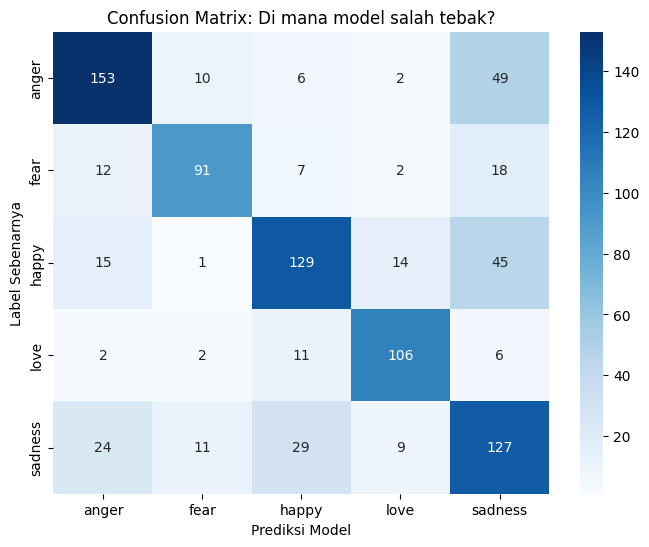

In [29]:
# @title Laporan Evaluasi
predictions = trainer.predict(test_dataset)
preds = np.argmax(predictions.predictions, axis=1)

print("Laporan Klasifikasi:")
print(classification_report(test_labels, preds, target_names=label_map.keys()))

# Visualisasi Confusion Matrix
cm = confusion_matrix(test_labels, preds)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=label_map.keys(), yticklabels=label_map.keys())
plt.xlabel('Prediksi Model')
plt.ylabel('Label Sebenarnya')
plt.title('Confusion Matrix: Di mana model salah tebak?')
plt.show()

#Tahap 6: Prediksi Komentar YouTube
Saatnya menggunakan 'otak' yang sudah dilatih untuk menganalisis komentar netizen.

In [30]:
# @title Load & Preprocess Komentar YouTube
df_youtube = pd.read_csv('youtube_comments.csv')
print(f"Memuat {len(df_youtube)} komentar.")

print("⏳ Membersihkan komentar YouTube...")
# Pastikan kolom textDisplay ada
text_col = 'textDisplay' if 'textDisplay' in df_youtube.columns else df_youtube.columns[0]
df_youtube = df_youtube.dropna(subset=[text_col])

df_youtube['clean_text'] = df_youtube[text_col].progress_apply(full_processing)
df_youtube = df_youtube[df_youtube['clean_text'].str.strip() != '']

print(f"Siap diprediksi: {len(df_youtube)} komentar bersih.")

Memuat 11271 komentar.
⏳ Membersihkan komentar YouTube...


100%|██████████| 11271/11271 [00:00<00:00, 22218.77it/s]

Siap diprediksi: 10984 komentar bersih.


In [31]:
# @title Jalankan Prediksi (Inference)
def predict_batch(texts, batch_size=32):
    model.eval()
    all_preds = []
    all_confs = []

    for i in tqdm(range(0, len(texts), batch_size), desc="Inference"):
        batch = texts[i:i+batch_size]
        inputs = tokenizer(batch, truncation=True, padding=True, max_length=128, return_tensors='pt').to(device)
        with torch.no_grad():
            outputs = model(**inputs)
            probs = torch.softmax(outputs.logits, dim=1)
            conf, pred = torch.max(probs, dim=1)
            all_preds.extend(pred.cpu().numpy())
            all_confs.extend(conf.cpu().numpy())
    return all_preds, all_confs

preds, confs = predict_batch(df_youtube['clean_text'].tolist())

df_youtube['emotion_label'] = [id_map[p] for p in preds]
df_youtube['confidence'] = confs

print("Prediksi selesai!")

Inference: 100%|██████████| 344/344 [00:47<00:00,  7.17it/s]

Prediksi selesai!


#Tahap 7: Visualisasi & Insight
Bagian ini yang paling penting untuk **Presentasi**. Kita akan melihat pola emosi netizen.

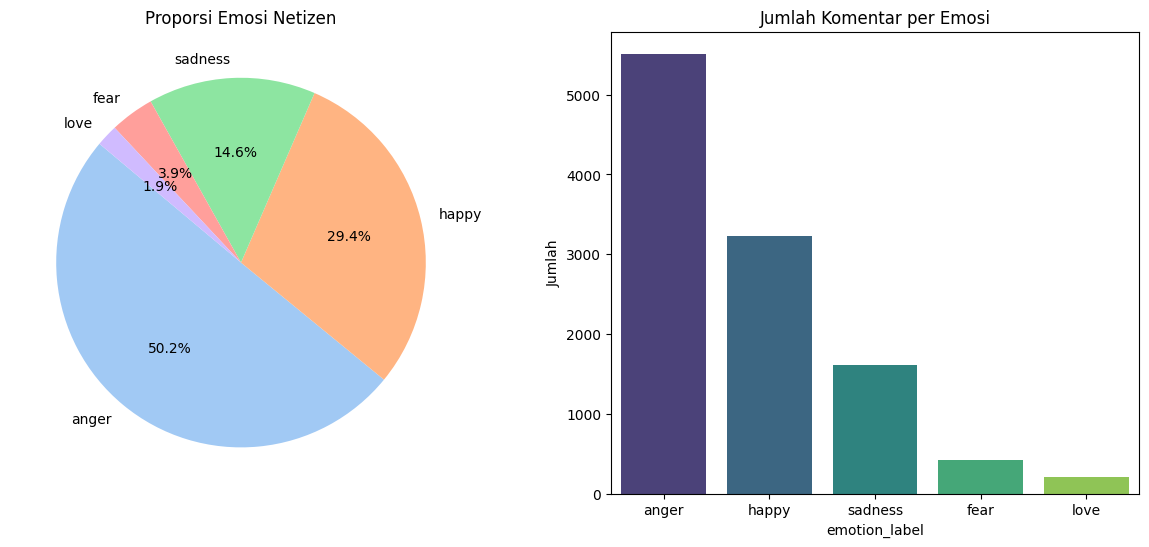

In [32]:
# @title 1. Distribusi Emosi (Pie Chart & Bar Chart)
emotion_counts = df_youtube['emotion_label'].value_counts()

plt.figure(figsize=(15, 6))

# Pie Chart
plt.subplot(1, 2, 1)
plt.pie(emotion_counts, labels=emotion_counts.index, autopct='%1.1f%%', startangle=140, colors=sns.color_palette('pastel'))
plt.title('Proporsi Emosi Netizen')

# Bar Chart
plt.subplot(1, 2, 2)
sns.barplot(x=emotion_counts.index, y=emotion_counts.values, palette='viridis')
plt.title('Jumlah Komentar per Emosi')
plt.ylabel('Jumlah')
plt.show()

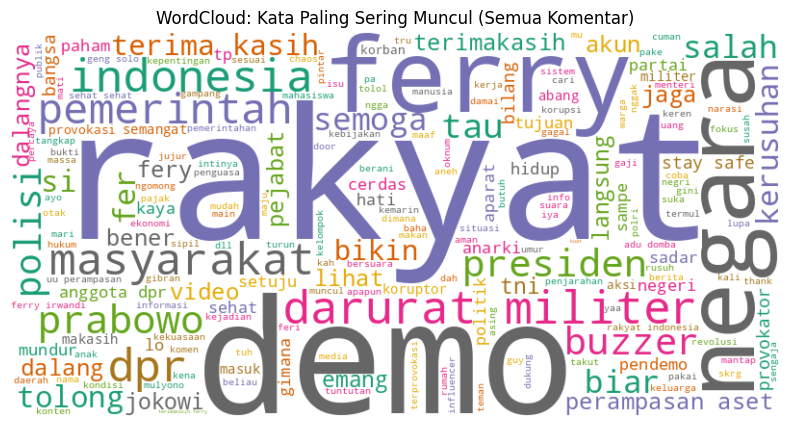

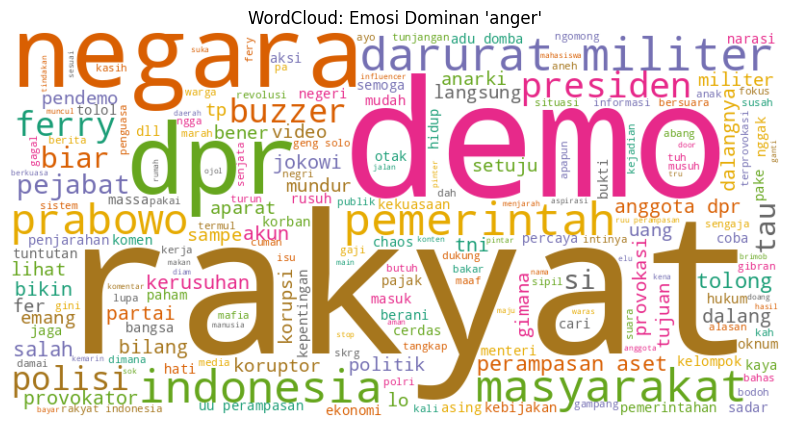

In [33]:
# @title 2. WordCloud (Apa yang sering dibicarakan?)
def show_wordcloud(text_data, title):
    text = ' '.join(text_data.astype(str))
    wc = WordCloud(width=800, height=400, background_color='white', colormap='Dark2').generate(text)
    plt.figure(figsize=(10, 5))
    plt.imshow(wc, interpolation='bilinear')
    plt.axis('off')
    plt.title(title)
    plt.show()

# WordCloud Global
show_wordcloud(df_youtube['clean_text'], "WordCloud: Kata Paling Sering Muncul (Semua Komentar)")

# WordCloud per Emosi Dominan
top_emotion = emotion_counts.idxmax()
subset = df_youtube[df_youtube['emotion_label'] == top_emotion]['clean_text']
show_wordcloud(subset, f"WordCloud: Emosi Dominan '{top_emotion}'")

In [34]:
# @title 3. Contoh Komentar dengan Prediksi Paling Yakin (High Confidence)
print("Komentar dengan Confidence Score Tertinggi:")
top_conf = df_youtube.sort_values('confidence', ascending=False).head(10)

for i, row in top_conf.iterrows():
    print(f"\n[{row['emotion_label'].upper()}] - Confidence: {row['confidence']:.4f}")
    print(f"\"{row[text_col]}\"")

Komentar dengan Confidence Score Tertinggi:

[FEAR] - Confidence: 0.9871
"Dah bang ngeri.. biet klo di terusin"

[HAPPY] - Confidence: 0.9869
"Terimakasih atas pembelajarannya bang, sehat selalu bang Ferry Irwandi dan team🔥"

[FEAR] - Confidence: 0.9869
"Ngeri ngeri sedapya keadaan negara kita"

[HAPPY] - Confidence: 0.9866
"Terimakasih Bang Ferry atas wawasannya untuk membuka mata agar berfikir lebih cerdas lagi dlm segala hal untuk kedepannya"

[HAPPY] - Confidence: 0.9864
"makasiii bang ferry dan tim malaka project juga ,informasi yg disampaikan sangat bermanfaat, sehat selalu, panjang umur perjuangan✊️🙌"

[HAPPY] - Confidence: 0.9864
"Terimakasih bung, terimakasih atas pencerahan dan arahannya. Terimakasih juga telah membuka banyak pikiran dan semuanya, terimakasih telah memberi rakyat pencerahan. REVOLUSI🔥🔥🔥"

[HAPPY] - Confidence: 0.9863
"Komentar ini dibaca oleh orang yang akan sukses dimasa depan, Aamiin"

[HAPPY] - Confidence: 0.9862
"Terima kasih buat edukasinya selama ini ba

In [35]:
print("\n--- Contoh Komentar per Emosi (5 data per emosi) ---")

all_sample_comments = []
for emotion in df_youtube['emotion_label'].unique():
    print(f"\nEmosi: {emotion.upper()}")
    # Ambil 5 contoh komentar secara acak untuk setiap emosi
    # Pastikan ada cukup data untuk di-sample, jika tidak ambil semua yang ada
    num_samples = min(5, len(df_youtube[df_youtube['emotion_label'] == emotion]))
    if num_samples > 0:
        sample_comments = df_youtube[df_youtube['emotion_label'] == emotion].sample(n=num_samples, random_state=42).copy()
        sample_comments['predicted_emotion'] = emotion
        all_sample_comments.append(sample_comments[['textDisplay', 'clean_text', 'predicted_emotion']])
    else:
        print(f"Tidak ada komentar untuk emosi {emotion}")

# Gabungkan semua contoh menjadi satu DataFrame
if all_sample_comments:
    df_sample_comments = pd.concat(all_sample_comments, ignore_index=True)
    display(df_sample_comments)
else:
    print("Tidak ada komentar untuk ditampilkan.")



--- Contoh Komentar per Emosi (5 data per emosi) ---

Emosi: HAPPY

Emosi: SADNESS

Emosi: ANGER

Emosi: FEAR

Emosi: LOVE


,textDisplay,clean_text,predicted_emotion
0,Puji Tuhan . Tulisan dipojok kirinya udah hila...,puji tuhan tulisan dipojok kirinya hilang teri...,happy
1,Jika Tim Malaka Project dan Tim Kementrian Keg...,tim malaka project tim kementrian kegelapan me...,happy
2,semoga Alloh tolong indonesia.<br>mari berfiki...,semoga alloh tolong indonesia mari berfikir se...,happy
3,"semalam di JEPARA juga terjadi demo, demo berj...",semalam jepara demo demo berjalan lancar polre...,happy
4,terima kasih telah ada dan berkenenan untuk ma...,terima kasih berkenenan masyarakat republik fe...,happy
5,"Truth Euforia...over Conciousness,.Hyperbolic ...",truth euforiaover conciousnesshyperbolic mind ...,sadness
6,"<a href=""https://www.youtube.com/watch?v=3FwSe...",emang tuntutan masyarakat kagak melebar,sadness
7,Paham dong siapa dalang nya.<br>Kalo Uda masiv...,paham dalang uda masive aksi masyarakat darura...,sadness
8,"Prabowo turun, gibran naik 😂😂",prabowo turun gibran,sadness
9,Tapi apa si yang bisa bikin anak usia 18 tahun...,si bikin anak usia terobsesi polisi tunjangan ...,sadness


In [44]:
# @title 4. Coba Prediksi Teks Sendiri
# Silakan masukkan kalimat Anda di bawah ini untuk melihat hasil prediksi model:

# BUKAN 1 TEKS LAGI, TAPI 10 TEKS
input_texts = [
    "dibayar berapa lu dek?",
    "video ini keren banget sumpah",
    "aku capek banget hari ini",
    "kok bisa sih pemerintah kayak gini",
    "makasih banyak ya bang",
    "ini parah sih kelakuannya",
    "gue seneng banget sumpah",
    "kecewa sama hasil akhirnya",
    "udah biasa lah kejadian gini",
    "tolong jelasin maksudnya apa",
    "LOVE  BANG FERRY"
]

def predict_single(text):
    if not isinstance(text, str) or text.strip() == "":
        return "neutral", 0.0

    clean = full_processing(text)
    inputs = tokenizer(
        clean,
        return_tensors="pt",
        truncation=True,
        max_length=128
    ).to(device)

    with torch.no_grad():
        outputs = model(**inputs)
        probs = torch.softmax(outputs.logits, dim=1)
        conf, pred = torch.max(probs, dim=1)
        label_id = pred.item()
        confidence = conf.item()

    emotion = id_map[label_id]
    return emotion, confidence

# PREDIKSI UNTUK 10 TEKS
for i, input_text in enumerate(input_texts, start=1):
    emotion, conf = predict_single(input_text)
    print(f"{i}. Kalimat: \"{input_text}\"")
    print(f"   Prediksi Emosi: {emotion.upper()} (Keyakinan: {conf:.2%})\n")


1. Kalimat: "dibayar berapa lu dek?"
   Prediksi Emosi: ANGER (Keyakinan: 77.03%)

2. Kalimat: "video ini keren banget sumpah"
   Prediksi Emosi: HAPPY (Keyakinan: 94.76%)

3. Kalimat: "aku capek banget hari ini"
   Prediksi Emosi: SADNESS (Keyakinan: 87.84%)

4. Kalimat: "kok bisa sih pemerintah kayak gini"
   Prediksi Emosi: ANGER (Keyakinan: 95.10%)

5. Kalimat: "makasih banyak ya bang"
   Prediksi Emosi: HAPPY (Keyakinan: 97.27%)

6. Kalimat: "ini parah sih kelakuannya"
   Prediksi Emosi: ANGER (Keyakinan: 95.77%)

7. Kalimat: "gue seneng banget sumpah"
   Prediksi Emosi: HAPPY (Keyakinan: 94.07%)

8. Kalimat: "kecewa sama hasil akhirnya"
   Prediksi Emosi: SADNESS (Keyakinan: 66.48%)

9. Kalimat: "udah biasa lah kejadian gini"
   Prediksi Emosi: ANGER (Keyakinan: 45.40%)

10. Kalimat: "tolong jelasin maksudnya apa"
   Prediksi Emosi: ANGER (Keyakinan: 81.99%)

11. Kalimat: "LOVE  BANG FERRY"
   Prediksi Emosi: LOVE (Keyakinan: 95.85%)



In [37]:
# @title Simpan Hasil ke CSV
output_name = 'youtube_comments_bert_labeled.csv'
df_youtube.to_csv(output_name, index=False)
print(f"Hasil disimpan ke: {output_name}")

try:
    files.download(output_name)
except:
    pass

Hasil disimpan ke: youtube_comments_bert_labeled.csv


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>